# <span style="font-weight:bold; font-size:1.25em">Box Plots</span>

<span style="color:red; font-weight:bold; font-size:1.5em">The functions</span> <span style="color:blue; font-weight:bold; font-size:1.5em">box()</span> <span style="color:red; font-weight:bold; font-size:1.5em"> and </span> <span style="color:blue; font-weight:bold; font-size:1.5em">boxes()</span> <span style="color:red; font-weight:bold; font-size:1.5em"> work with tables, but </span> <span style="color:blue; font-weight:bold; font-size:1.5em">box()</span> <span style="color:red; font-weight:bold; font-size:1.5em"> can also work with array input.</span></br>

These functions allow students to intuitvely create box plots at every step of the course. They possess the flexibility to create a single box plot or side-by-side box plots based upon a grouping variable.

In [61]:
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats

In [62]:
## Read in a CSV data file from the web.

pers = Table.read_table('http://faculty.ung.edu/rsinn/personality.csv')
births = Table.read_table('https://faculty.ung.edu/rsinn/data/baby.csv')

## <span style="font-weight:bold; font-size:1.15em">The box() Function</span> 
The code block below defines the function which is coded to accept:
1. table name, numeric variable column name, and showmeans value, or
2. array name, plot title, and showmeans value.

In [63]:
def box(data, num = None, sm = False):
  if isinstance(data, Table):
    df = data.to_df()
    sns.boxplot(data=df, y=num, width=0.45, showmeans=sm)  ;
    plots.title(f'Boxplot of {num}')
    plots.xticks([], [])
    plots.show()  
  else:
    if num == True:
      sm = True  ;  num = 'Variable'
    if num == None:
      num = 'Variable'
    plots.figure(figsize=(6, 5))
    sns.boxplot(data, width=0.45, showmeans=sm)  ;
    plots.title(f'Boxplot of {num}')
    plots.xticks([], [])
    plots.show()  
  return

## Example of **box()** function working:

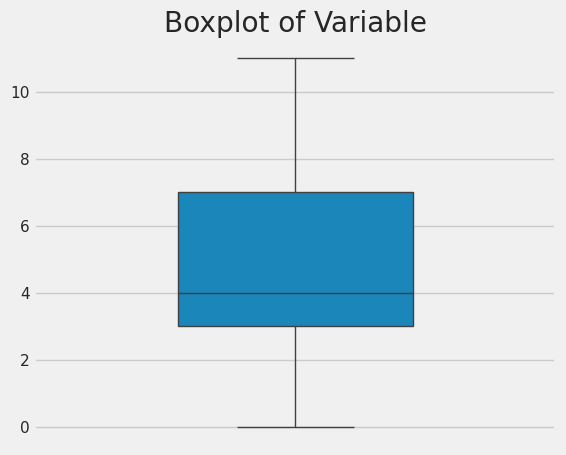

In [64]:
box(pers.column('Narc'))

## <span style="font-weight:bold; font-size:1.15em">The boxes() Function</span> 
The code block below defines a function which is coded to accept 
1. table name
2. numeric variable column name
3. grouping variable column name, and
4. showmeans value.
The function will graph multiple box plots for a numerica variable grouped by a category variable.

In [65]:
def boxes(tab, num = None, cat = None, sm = False):
# Dictionary for median line styling (blue) and mean marker styling (golden triangle)
  median_props = { "color": "darkblue", "linewidth": 0.75 } ; mean_props = { "marker": "^", "markerfacecolor": "gold", "markeredgecolor": "black", "markersize": 7 }
  sns.set_theme(style="darkgrid")
  plots.figure(figsize=(8, 7))
  if isinstance(tab, Table):
    df = tab.to_df()
    n_categories = df[cat].nunique()
    max_label_length = df[cat].astype(str).str.len().max()
    rot = 45 if n_categories > 5 or max_label_length > 10 else 0
    sns.boxplot(data=tab, x=cat, y=num, width=0.75, showmeans=sm, medianprops=median_props, meanprops=mean_props)
    plots.xticks(rotation=rot, ha="right" if rot > 0 else "center")
    plots.title(f'Boxplot of {num} Grouped by {cat}')
    plots.show()
  else:
    arrays = list(tab.values()) ; labels = list(tab.keys())
    sns.set_theme(style="darkgrid")
    sns.boxplot( data=arrays, color="#1f77b4", width=0.75, showmeans=sm, medianprops=median_props, meanprops=mean_props)
    rot = 45 if len(arrays) > 5 else 0
    plots.xticks(ticks=range(len(labels)), labels=labels, rotation=rot)
    title_str = num if isinstance(num, str) else "Arrays"
    plots.title(f'Boxplot of {title_str}')
    plots.show() 
  return

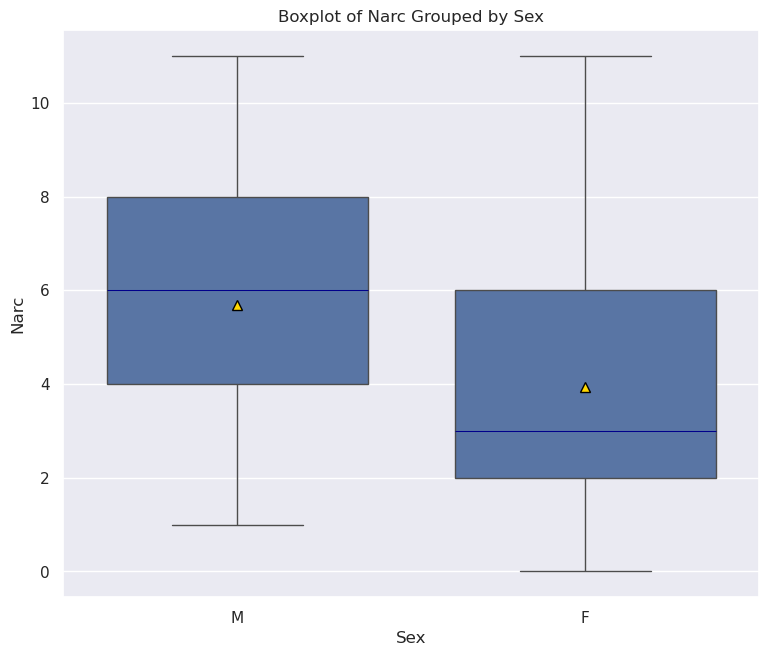

In [66]:
boxes(pers, 'Narc', 'Sex', True)

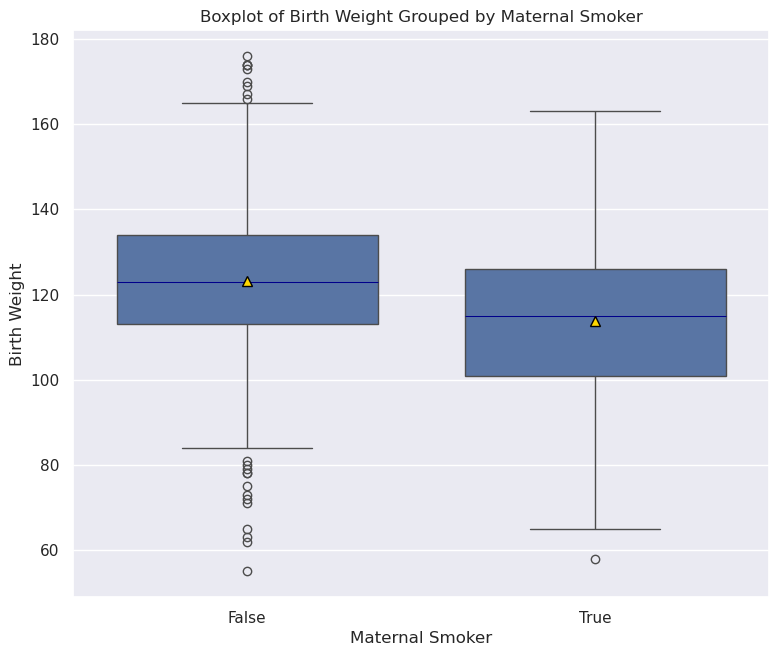

In [67]:
boxes(births, 'Birth Weight','Maternal Smoker', True)

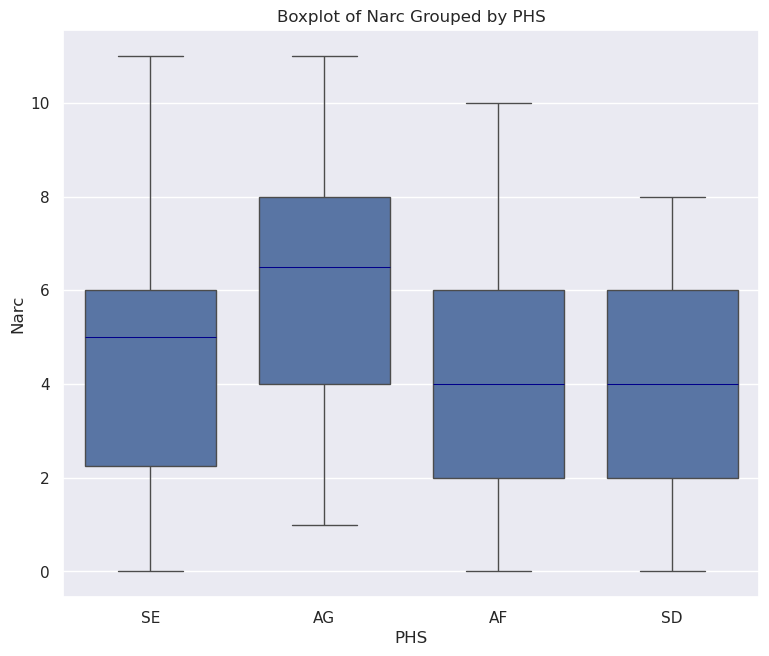

In [68]:
boxes(pers, 'Narc', 'PHS')

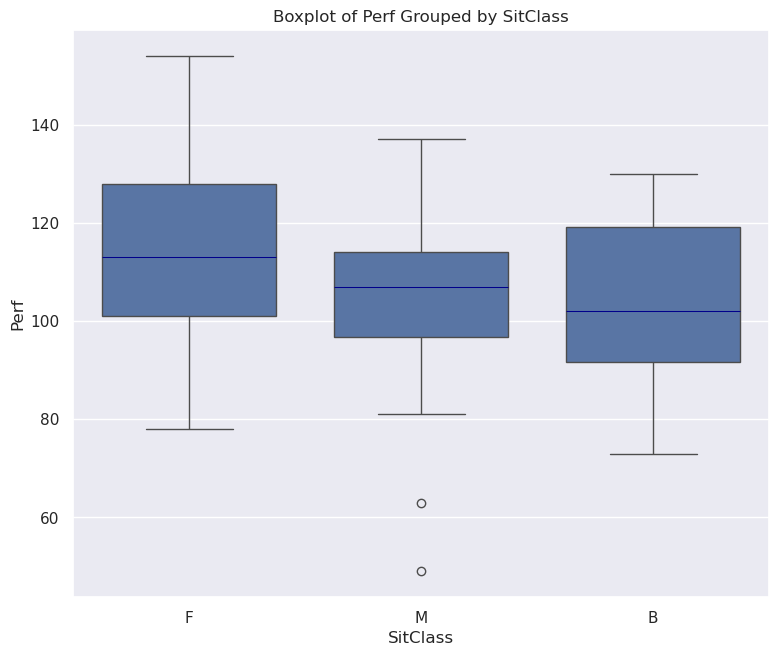

In [69]:
boxes(pers, 'Perf','SitClass')

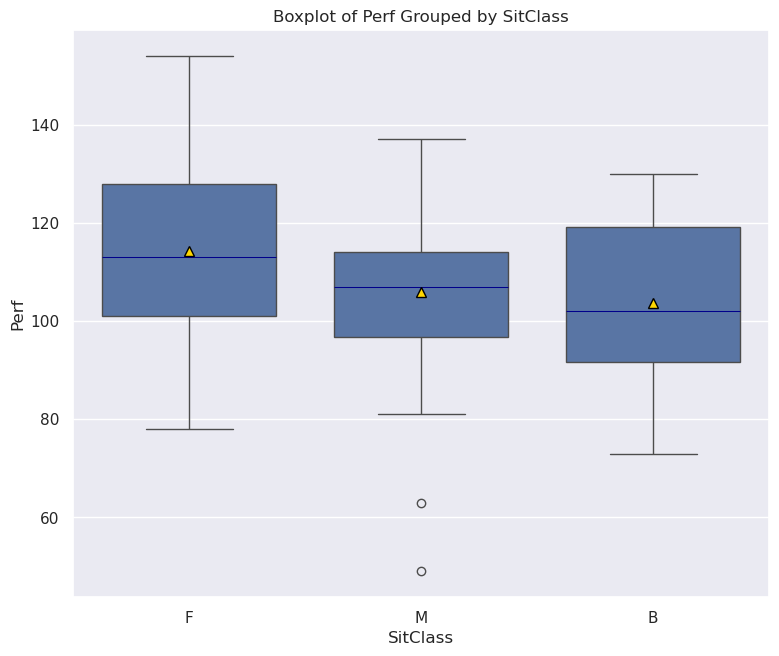

In [70]:
boxes(pers, 'Perf', 'SitClass', True)

In [71]:
temp = Table.read_table("Penicillin measurements.csv")
penicillin = temp.relabel(1, "E. coli").relabel(2, "S. epidermidis").relabel(0,"Compound")
E_ag5 = penicillin.where("Compound", "AG (light blue) 5 ppm").column(1)
E_ag10 = penicillin.where("Compound", "AG (purple) 10 ppm").column(1)
E_ampic = penicillin.where("Compound", "Ampicillin").column(1)
E_er5 = penicillin.where("Compound", "ER (green) 5ppm").column(1)
E_er10 = penicillin.where("Compound", "ER (yellow) 10 ppm").column(1)
E_jh5 = penicillin.where("Compound", "JH (red) 5 ppm").column(1)
E_jh10 = penicillin.where("Compound", "JH (orange) 10 ppm").column(1)
E_penic = penicillin.where("Compound", "Penicillin").column(1)
E_h2o = penicillin.where("Compound", "Water").column(1)
penicillin.show(3)

Compound,E. coli,S. epidermidis
Ampicillin,15,34
Ampicillin,19,35
Penicillin,11,33


In [72]:
my_dict = {'E_ag5':E_ag5,'E_ag10':E_ag10,'E_ampic':E_ampic,'E_er5':E_er5,
  'E_er10':E_er10,'E_jh5':E_jh5,'E_jh10':E_jh10,'E_penic':E_penic, 'E_h2o':E_h2o}

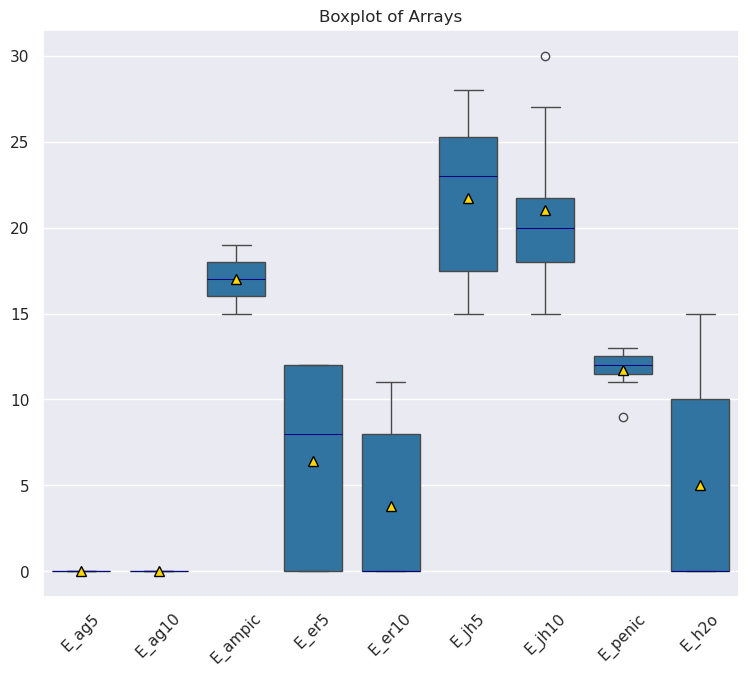

In [73]:
boxes(my_dict, sm=True)